## Experiment 7: Time Series Analysis of Stock Market Data

**Aim:** To perform time series analysis on stock price data to identify trends, patterns and seasonality, and to build a simple model to forecast future stock prices.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(6)
dates = pd.date_range("2025-01-01", periods=240)
price = 100 + np.cumsum(np.random.normal(0.3, 2, 240))
df = pd.DataFrame({
    "date": dates,
    "close": np.round(price, 2),
    "volume": np.random.randint(100000, 900000, 240),
})
df.head()

,date,close,volume
0,2025-01-01,99.68,592896
1,2025-01-02,101.43,231931
2,2025-01-03,102.17,751394
3,2025-01-04,100.67,260365
4,2025-01-05,96.00,420685


In [3]:
print("total rows:", df.shape)

total rows: (240, 3)


In [4]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df.head()

,close,volume
date,,
2025-01-01,99.68,592896
2025-01-02,101.43,231931
2025-01-03,102.17,751394
2025-01-04,100.67,260365
2025-01-05,96.00,420685


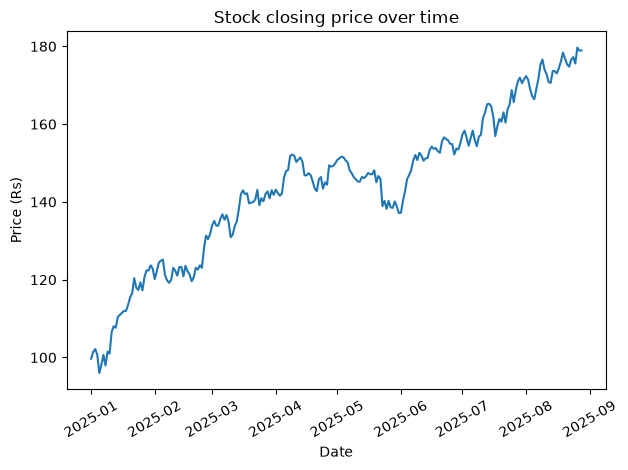

In [5]:
plt.plot(df.index, df["close"])
plt.title("Stock closing price over time")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [6]:
df["ma20"] = df["close"].rolling(20).mean()
df["ma50"] = df["close"].rolling(50).mean()
df.head(55).tail()

,close,volume,ma20,ma50
date,,,,
2025-02-20,120.61,285589,121.9040,115.3262
2025-02-21,123.05,221667,122.0480,115.7586
2025-02-22,122.60,673705,122.0690,116.1672
2025-02-23,123.70,573534,122.0355,116.6278
2025-02-24,123.05,178243,121.9430,117.1688


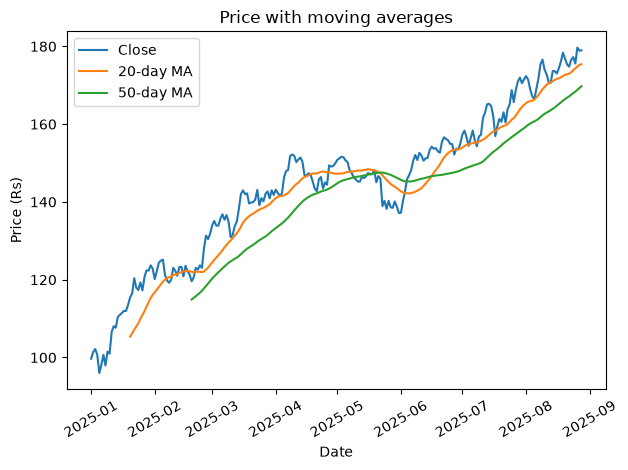

In [7]:
plt.plot(df.index, df["close"], label="Close")
plt.plot(df.index, df["ma20"], label="20-day MA")
plt.plot(df.index, df["ma50"], label="50-day MA")
plt.title("Price with moving averages")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
df["month"] = df.index.month
monthly = df.groupby("month")["close"].mean()
print(monthly)

month
1    110.577742
2    123.288571
3    138.346774
4    147.082333
5    145.217097
6    151.381667
7    162.137097
8    173.938929
Name: close, dtype: float64


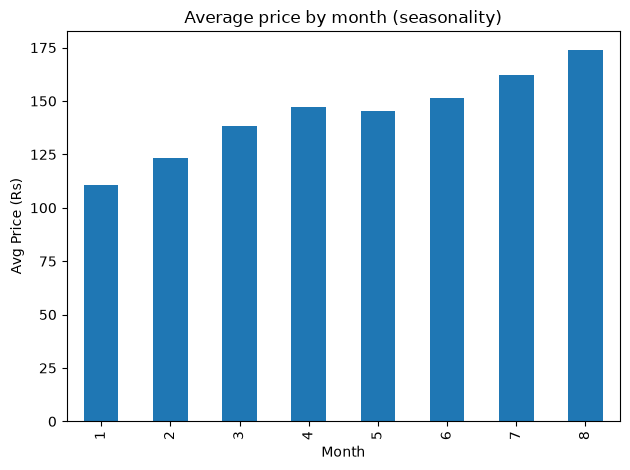

In [9]:
monthly.plot(kind="bar")
plt.title("Average price by month (seasonality)")
plt.xlabel("Month")
plt.ylabel("Avg Price (Rs)")
plt.tight_layout()
plt.show()

In [10]:
print("price-volume correlation:", df["close"].corr(df["volume"]))

price-volume correlation: -0.037906536412319884


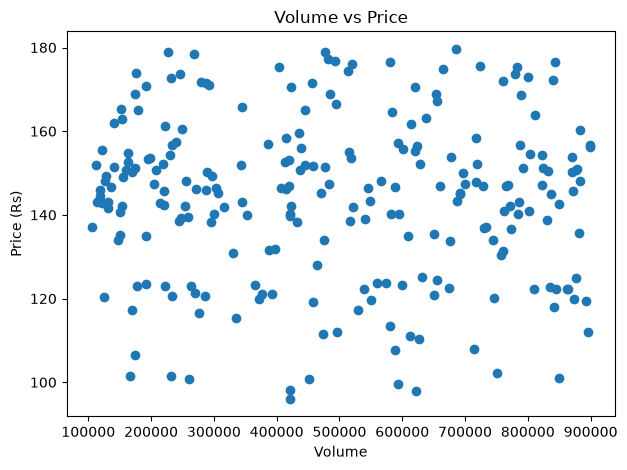

In [11]:
plt.scatter(df["volume"], df["close"])
plt.title("Volume vs Price")
plt.xlabel("Volume")
plt.ylabel("Price (Rs)")
plt.tight_layout()
plt.show()

In [12]:
alpha = 0.3
s = [df["close"].iloc[0]]
for p in df["close"].iloc[1:]:
    s.append(alpha * p + (1 - alpha) * s[-1])
df["forecast"] = s
df.tail()

,close,volume,ma20,ma50,month,forecast
date,,,,,,
2025-08-24,177.23,482304,173.8615,168.0058,8,176.202675
2025-08-25,175.59,724136,174.3210,168.3504,8,176.018872
2025-08-26,179.68,685703,174.8565,168.8258,8,177.117211
2025-08-27,178.90,477692,175.2195,169.3176,8,177.652047
2025-08-28,178.95,227548,175.4005,169.7606,8,178.041433


In [13]:
future = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=30)
last = s[-1]
trend = (s[-1] - s[-30]) / 30
fp = [last + trend * i for i in range(1, 31)]
print("next 5 forecast values:", [round(x, 2) for x in fp[:5]])

next 5 forecast values: [np.float64(178.33), np.float64(178.62), np.float64(178.91), np.float64(179.2), np.float64(179.49)]


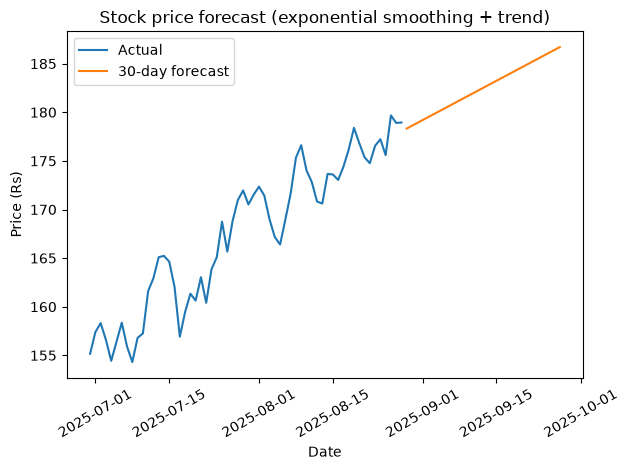

In [14]:
plt.plot(df.index[-60:], df["close"][-60:], label="Actual")
plt.plot(future, fp, label="30-day forecast")
plt.title("Stock price forecast (exponential smoothing + trend)")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
print("done")

done
